
<table style="background-color: transparent;">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1">Computación Cuántica</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%">
            <font size="6" color="#6366F1">
                Laboratorio 7:<br>
                Aprendizaje Automático Cuántico y Algoritmos Variacionales de Optimización
            </font>
        </td>
    </tr>
</table>



$$
\begin{gathered}
\phantom{\Large X}\\[5pt]
\huge \text{Redes Neuronales Cuánticas (QNN)}
\end{gathered}
$$



$$
\begin{gathered}
\phantom{\Large X}
\huge \text{y}
\end{gathered}
$$


$$
\begin{gathered}
\phantom{\Large X}
\huge \text{Clasificadores Cuánticos Variacionales (VQC)}
\end{gathered}
$$


### *Autor: Sebastián González Juárez*


---

# **Contenido**

1. [**Fundamentos de Redes Neuronales (NN)**](#seccion-1)
2. [**Algoritmos Cuánticos Variacionales (VQA)**](#seccion-2)
3. [**Construcción de una Red Neuronal Cuántica Variacional (QNN)**](#seccion-3)
4. [**Métodos de Medición y Clasificación Cuántica Variacional**](#seccion-4)

<a name="seccion-1"></a>

# **1. Fundamentos de Redes Neuronales (NN)**


Las **redes neuronales (Neural Networks, NN)** son modelos de aprendizaje automático capaces de identificar patrones y realizar predicciones ajustando sus parámetros a partir de datos.

Estudiaremos cómo se construyen y entrenan, para después trasladar estos principios a los **circuitos cuánticos variacionales**.



<p align="center">
  <img src="https://miro.medium.com/v2/resize:fit:640/0*0gv8Cs0UaB49ZNKZ.gif" width="550">
</p>



## 1.1. Redes neuronales

Una **red neuronal** está formada por neuronas artificiales conectadas y organizadas en capas. Cada neurona recibe datos, calcula una combinación ponderada y aplica una **función de activación**.

Matemáticamente, una neurona se describe mediante:

$$
\boxed{a=f\left(\sum_{i=1}^{n}w_ix_i+b\right)}
$$

donde:

- $x_i$: datos de entrada.
- $w_i$: pesos que determinan la importancia de cada entrada.
- $b$: sesgo (*bias*).
- $f$: función de activación, que puede introducir no linealidad.
- $a$: salida de la neurona.


<p align="center">
  <img src="https://cdn-images-1.medium.com/max/732/1*KNZZYteeBqkJViS1_LT1CQ.gif" width="550">
</p>
<p align="center">
  <em>Funcionamiento de una neurona artificial (perceptrón).</em>
</p>


Al conectar múltiples neuronas, obtenemos una red organizada en tres tipos de capas:

1. **Entrada (Input):** recibe las características de los datos.
2. **Ocultas (Hidden):** transforman la información mediante pesos, sesgos y funciones de activación.
3. **Salida (Output):** genera las predicciones del modelo.

**[Insertar imagen: arquitectura de una red neuronal multicapa]**

Una red neuronal aprende ajustando sus **pesos y sesgos** para producir predicciones cada vez más cercanas a los valores reales.


## 1.2. Proceso de aprendizaje

El **entrenamiento** consiste en ajustar los parámetros de una red neuronal para minimizar el error entre sus predicciones y los valores reales.

Este proceso se repite mediante cuatro pasos:

#### ***I.** Propagación hacia adelante (Forward Propagation)*

Los datos atraviesan las capas de la red hasta producir una predicción:

$$
\boxed{\hat y=f_\theta(\mathbf{x})}
$$

donde $\mathbf{x}$ representa los datos de entrada, $\theta$ los parámetros de la red y $\hat y$ la predicción.


<p align="center">
  <img src="https://miro.medium.com/v2/resize:fit:640/1*63sGPbvLLpvlD16hG1bvmA.gif" width="550">
</p>
<p align="center">
  <em>Propagación de información en una red neuronal para el reconocimiento de dígitos manuscritos.</em>
</p>


#### ***II.** Función de pérdida (Loss Function)*

Comparamos la predicción $\hat y$ con la etiqueta real $y$ mediante una función de pérdida:

$$
\boxed{\mathcal{L}(\theta)=\ell(f_\theta(\mathbf{x}),y)}
$$

La función $\ell$ cuantifica el error de predicción. Para múltiples muestras, calculamos habitualmente la pérdida promedio:

$$
\mathcal{L}(\theta)=\frac{1}{N}\sum_{i=1}^{N}
\ell(f_\theta(\mathbf{x}_i),y_i).
$$

La función de pérdida cuantifica qué tan diferente es la predicción del modelo respecto al valor real.
En el siguiente ejemplo, conforme el modelo se ajusta, las predicciones se acercan a los datos y el error disminuye.

<p align="center">
  <img src="https://gbhat.com/assets/gifs/linear_regression.gif" width="520">
</p>
<p align="center">
  <em>Ajuste iterativo de un modelo y reducción del error de predicción.</em>
</p>


Durante la **retropropagación (Backpropagation)**, el error se propaga desde la capa de salida hacia las capas anteriores. Mediante la **regla de la cadena**, se calculan los gradientes de la función de pérdida respecto a cada parámetro de la red:

$$
\boxed{\nabla_\theta\mathcal{L}(\theta)}
$$

Estos gradientes indican cómo influye cada parámetro en el error y serán utilizados posteriormente por el optimizador.



<p align="center">
  <img src="https://developer-blogs.nvidia.com/wp-content/uploads/2022/02/DS-Guide-to-Gradient-Descent_Pic5.gif" width="520">
</p>
<p align="center">
  <em>Retropropagación de los gradientes a través de las capas de una red neuronal.</em>
</p>


#### ***IV.** Optimización (Optimization)*

Un optimizador actualiza los parámetros utilizando los gradientes. Mediante **descenso por gradiente**:

$$
\boxed{\theta_{t+1}=\theta_t-\eta\nabla_\theta\mathcal{L}(\theta_t)}
$$

donde:

- $\theta_t$: parámetros en la iteración actual.
- $\eta$: tasa de aprendizaje (*learning rate*).
- $\nabla_\theta\mathcal{L}$: gradiente de la pérdida.



<p align="center">
  <img src="https://sar-gupta.github.io/images/2017-10-20-gradient-descent/05.gif" width="520">
</p>
<p align="center">
  <em>Descenso por gradiente: actualización iterativa de los parámetros para minimizar la función de pérdida.</em>
</p>


### Objetivo del entrenamiento

Repetimos el ciclo hasta encontrar parámetros que minimicen la función de pérdida:

$$
\boxed{\theta^*=\underset{\theta}{\operatorname{argmin}}\;\mathcal{L}(\theta)}
$$

Este mismo principio de **optimización de parámetros** es la base de los **Algoritmos Cuánticos Variacionales (VQA)**, donde sustituiremos el modelo neuronal clásico por un circuito cuántico parametrizado.



<a name="seccion-2"></a>

# **2. Algoritmos Cuánticos Variacionales (VQA)**

Los **Algoritmos Cuánticos Variacionales (Variational Quantum Algorithms, VQA)** combinan un **procesamiento cuántico** con un **procesamiento clásico** para resolver un problema mediante un ciclo iterativo de optimización.

Dentro de esta familia se encuentran algoritmos como **VQE**, **QAOA** y los **Clasificadores Cuánticos Variacionales (VQC)**.

En este laboratorio nos enfocaremos únicamente en los **VQC**, ya que constituyen una de las formas más directas de construir modelos de aprendizaje automático cuántico.

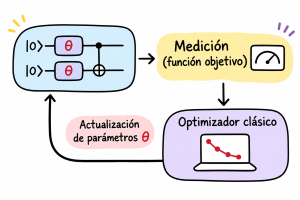

## 2.1. Esquema general de un VQC

La siguiente figura muestra el flujo general de un **Clasificador Cuántico Variacional (VQC)**.

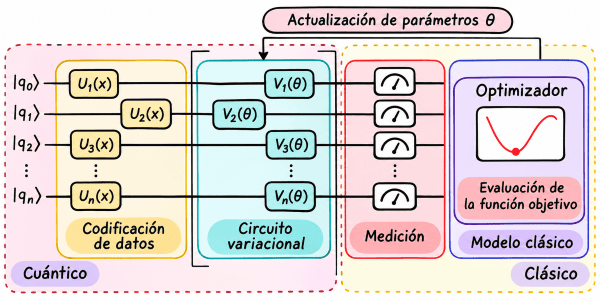

En la parte cuántica del diagrama se distinguen tres etapas principales:

1. **Codificación de datos**: los datos de entrada se incorporan al circuito mediante compuertas representadas como $U_1(x), U_2(x), U_3(x), \ldots, U_n(x)$.

2. **Circuito variacional**: después de la codificación, el sistema atraviesa un conjunto de operaciones parametrizadas representadas como $V_1(\theta), V_2(\theta), V_3(\theta), \ldots, V_n(\theta)$. Estas operaciones contienen los parámetros ajustables del modelo.

3. **Medición**: al final del circuito, se realiza una medición para extraer información clásica del sistema cuántico.

Posteriormente, en la parte clásica del esquema, se llevan a cabo dos pasos adicionales:

4. **Evaluación de la función objetivo**: los resultados de medición se utilizan para calcular una cantidad que indica qué tan bien está funcionando el modelo.

5. **Optimizador clásico**: con base en esa evaluación, un optimizador actualiza los parámetros $\theta$ del circuito variacional.

Este proceso se repite de forma iterativa mediante la **actualización de parámetros**, dando lugar al ciclo híbrido cuántico-clásico característico de los VQA.

## 2.2. Redes Neuronales Cuánticas (QNN)

Un **Clasificador Cuántico Variacional (VQC)** puede utilizarse como una **Red Neuronal Cuántica (Quantum Neural Network, QNN)** cuando sus parámetros se entrenan para producir predicciones a partir de datos de entrada.

En este contexto, la codificación de datos introduce la información clásica en el sistema cuántico, el circuito variacional actúa como la parte entrenable del modelo, y las mediciones permiten obtener salidas que pueden asociarse con clases.

Por tanto, un VQC puede emplearse como un modelo de clasificación entrenable, de manera análoga a una red neuronal en aprendizaje automático clásico.

En la siguiente sección construiremos una **QNN** basada en este esquema para realizar clasificación.


<a name="seccion-3"></a>

# **3. Construcción de una Red Neuronal Cuántica Variacional (QNN)**

En el laboratorio anterior utilizamos el conjunto de datos **Iris** para implementar un clasificador mediante **Quantum k-Nearest Neighbors (QkNN)**. Ahora retomaremos el mismo problema de clasificación multiclase utilizando una **Red Neuronal Cuántica Variacional (QNN)**.

Trabajaremos con las **150 muestras**, sus **cuatro características** y las **tres especies**. Para ello, construiremos un circuito de cuatro qubits compuesto por:

1. **Codificación cuántica (RY + IsingZZ):** incorpora las características mediante rotaciones y operaciones de interacción entre qubits vecinos.
2. **Ansatz variacional (RY + RZ + CNOT):** aplica transformaciones parametrizadas que se ajustarán durante el entrenamiento.

Implementaremos ambos componentes con **PennyLane y PyTorch** y construiremos un circuito compartido que posteriormente utilizaremos con tres estrategias distintas de medición y clasificación.

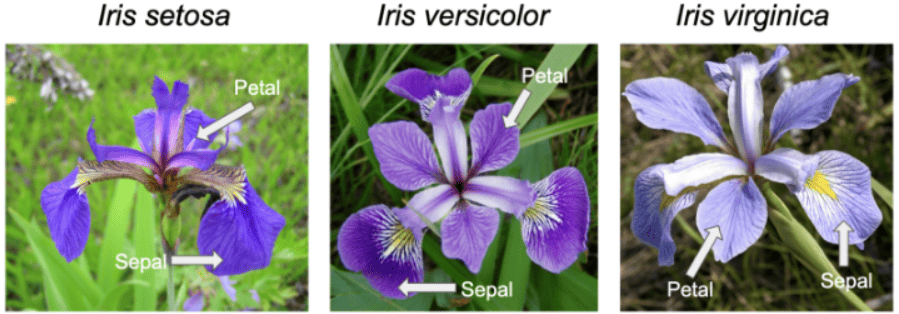

In [ ]:
%pip install -q pennylane torch scikit-learn matplotlib tqdm  # Instalar las bibliotecas de todas las secciones

In [ ]:
import numpy as np                                      # Operaciones numéricas
import matplotlib.pyplot as plt                         # Visualización de circuitos
import pennylane as qml                                 # Simulación cuántica
import torch                                            # Tensores y gradientes
from sklearn.datasets import load_iris                  # Conjunto de datos Iris
from sklearn.model_selection import train_test_split    # División estratificada de datos
from sklearn.preprocessing import MinMaxScaler          # Escalado angular
from tqdm.auto import tqdm                              # Barra de progreso del entrenamiento

SEMILLA = 87                                            # Semilla del laboratorio
NUM_QUBITS = 4                                          # Un qubit por característica
NUM_CAPAS = 2                                           # Dos capas del ansatz RY-RZ-CNOT
ALPHA = 0.5                                             # Factor de codificación del Feature Map
TIPO_DATO = torch.float64                               # Precisión doble

np.random.seed(SEMILLA)                                 # Fijar semilla de NumPy
torch.manual_seed(SEMILLA)                              # Fijar semilla de PyTorch
print(f"PennyLane: {qml.__version__} | PyTorch: {torch.__version__}")  # Versiones

PennyLane: 0.45.1 | PyTorch: 2.14.1+cu130


## 3.1. Codificación Cuántica de Datos (RY + IsingZZ)

Retomaremos las cuatro características y las tres especies de **Iris**. Dividiremos las 150 muestras de forma **estratificada** en tres conjuntos:

- **Entrenamiento (70 %):** ajustar los parámetros cuánticos.
- **Validación (15 %):** seleccionar la época con menor pérdida de validación.
- **Prueba (15 %):** evaluar una sola vez el modelo seleccionado.

El conjunto de entrenamiento contiene 105 muestras, mientras que validación y prueba contienen 22 y 23, respectivamente (el redondeo es necesario porque 150 × 0.15 = 22.5).

Antes de codificar, aplicaremos un escalado **Min-Max** al intervalo angular $[-\pi,\pi]$, ajustado **exclusivamente con entrenamiento**:

$$
\boxed{\phi_{ij}=-\pi+2\pi\frac{x_{ij}-x_j^{\min}}{x_j^{\max}-x_j^{\min}}}
$$

Los datos de validación y prueba utilizarán **el mismo escalador**, sin reajustarlo ni utilizar sus etiquetas durante el entrenamiento. Los ángulos de ambos conjuntos pueden quedar fuera de $[-\pi,\pi]$ si contienen valores fuera del rango observado en entrenamiento.

In [ ]:
iris = load_iris()                                      # Cargar las 150 muestras de Iris
X, y = iris.data, iris.target                           # Obtener características y etiquetas

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y)       # Separar 30 % y mantener proporciones por especie
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp)  # Dividir en validación y prueba estratificadas

scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))    # Definir el intervalo angular [-π, π]
X_train_t = torch.tensor(scaler.fit_transform(X_train), dtype=TIPO_DATO)  # Ajustar escalador solo con entrenamiento
X_val_t = torch.tensor(scaler.transform(X_val), dtype=TIPO_DATO)          # Transformar validación sin reajustar
X_test_t = torch.tensor(scaler.transform(X_test), dtype=TIPO_DATO)        # Transformar prueba sin reajustar

y_train_t = torch.tensor(y_train, dtype=torch.long)    # Etiquetas de entrenamiento
y_val_t = torch.tensor(y_val, dtype=torch.long)        # Etiquetas de validación
y_test_t = torch.tensor(y_test, dtype=torch.long)      # Etiquetas de prueba

print("Entrenamiento:", X_train_t.shape, np.bincount(y_train))  # Comprobar 105 muestras
print("Validación:   ", X_val_t.shape, np.bincount(y_val))      # Comprobar 22 muestras
print("Prueba:       ", X_test_t.shape, np.bincount(y_test))    # Comprobar 23 muestras
assert len(X_train_t) + len(X_val_t) + len(X_test_t) == 150    # Verificar que no falten muestras

Entrenamiento: torch.Size([105, 4]) [35 35 35]
Validación:    torch.Size([22, 4]) [8 7 7]
Prueba:        torch.Size([23, 4]) [7 8 8]


### **Mapa de características cuánticas (RY + IsingZZ)**

El **Feature Map** introduce las cuatro características mediante rotaciones $R_Y$ y agrega interacciones entre qubits vecinos con $\mathrm{IsingZZ}$.

**I. Codificación local:** cada característica angular $\phi_j$ determina una rotación

$$\boxed{R_Y(\alpha\phi_j)=\begin{pmatrix}\cos(\alpha\phi_j/2)&-\sin(\alpha\phi_j/2)\\\sin(\alpha\phi_j/2)&\cos(\alpha\phi_j/2)\end{pmatrix}}$$

**II. Interacción entre características:** para cada pareja vecina $(j,j+1)$, se aplica

$$\boxed{\mathrm{IsingZZ}_{j,j+1}(\gamma_j)=e^{-i\gamma_j Z_jZ_{j+1}/2},\qquad \gamma_j=\frac{\alpha^2\phi_j\phi_{j+1}}{2}}$$

Utilizaremos **$\alpha=0.5$**, cuatro rotaciones $R_Y$ y tres interacciones entre qubits vecinos: $(0,1)$, $(1,2)$ y $(2,3)$.

In [ ]:
def feature_map(x):
    for q in range(NUM_QUBITS):                         # Recorrer los cuatro qubits
        qml.RY(ALPHA * x[q], wires=q)                   # Incorporar cada característica mediante RY
    for q in range(NUM_QUBITS - 1):                     # Recorrer las tres parejas vecinas
        angulo = 0.5 * ALPHA**2 * x[q] * x[q + 1]      # Calcular la interacción de datos
        qml.IsingZZ(angulo, wires=[q, q + 1])           # Incorporar la correlación ZZ

**Visualización del Feature Map**

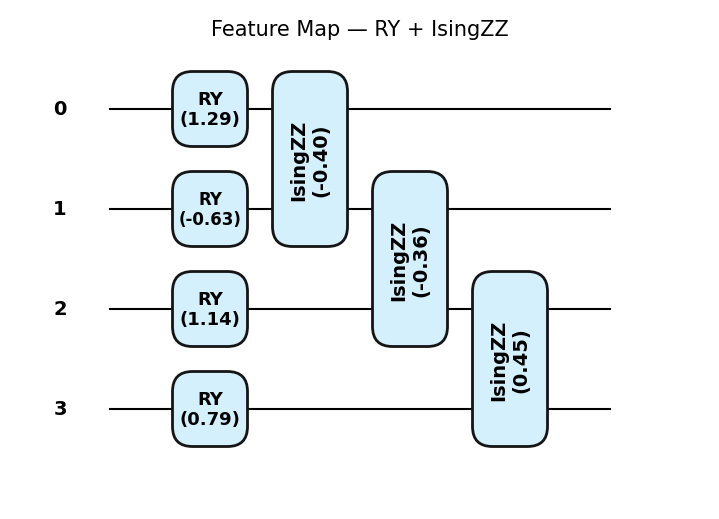

In [ ]:
fig, ax = qml.draw_mpl(feature_map, decimals=2, style="pennylane")(X_train_t[0])  # Dibujar una muestra de Iris
fig.suptitle("Feature Map — RY + IsingZZ", fontsize=15)                            # Identificar el circuito
plt.show()                                                                         # Mostrar la figura

## 3.2. Construcción del Ansatz Variacional (RY + RZ + CNOT)

El **ansatz** transforma el estado codificado mediante parámetros entrenables. Utilizaremos dos capas de **rotaciones $R_Y$, $R_Z$ y una cadena de CNOT**, como en el circuito de referencia.

**Rotaciones parametrizadas:**

$$
\boxed{R_Y(\theta)=\begin{pmatrix}\cos(\theta/2)&-\sin(\theta/2)\\\sin(\theta/2)&\cos(\theta/2)\end{pmatrix}},\qquad
\boxed{R_Z(\varphi)=\begin{pmatrix}e^{-i\varphi/2}&0\\0&e^{i\varphi/2}\end{pmatrix}}
$$

**Entrelazamiento lineal:**

$$\boxed{\mathrm{CNOT}_{0,1}\;\longrightarrow\;\mathrm{CNOT}_{1,2}\;\longrightarrow\;\mathrm{CNOT}_{2,3}}$$

Cada capa contiene $4\times2=8$ ángulos; con dos capas tendremos **16 parámetros cuánticos entrenables**.

In [ ]:
def ansatz_vqc(parametros):
    for capa in range(NUM_CAPAS):                       # Aplicar dos capas entrenables
        for q in range(NUM_QUBITS):                     # Recorrer los cuatro qubits
            qml.RY(parametros[capa, q, 0], wires=q)     # Aplicar rotación entrenable RY
            qml.RZ(parametros[capa, q, 1], wires=q)     # Aplicar rotación entrenable RZ
        for q in range(NUM_QUBITS - 1):                 # Entrelazar qubits vecinos
            qml.CNOT(wires=[q, q + 1])                  # Aplicar una cadena lineal de CNOT
        if capa < NUM_CAPAS - 1:                        # Separar visualmente las capas
            qml.Barrier(wires=range(NUM_QUBITS))        # Añadir barrera entre repeticiones

#### **Parámetros entrenables**

Los ángulos se organizan en un tensor

$$\boxed{\boldsymbol{\Theta}\in\mathbb{R}^{2\times4\times2},\qquad N_{\theta}=2\cdot4\cdot2=16}$$

Las dimensiones representan **capas, qubits y rotaciones ($R_Y$, $R_Z$)**. Inicializaremos todos los métodos con los mismos valores pequeños para que la comparación parta de una condición común.

Dimensiones: (2, 4, 2) | Parámetros cuánticos: 16


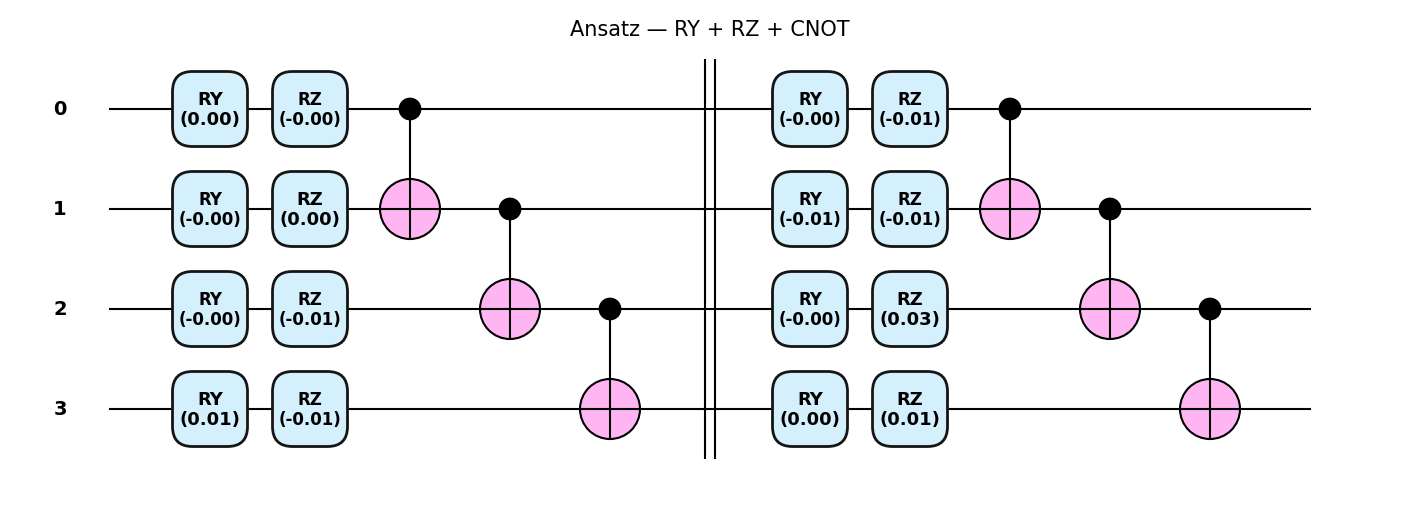

In [ ]:
generador = torch.Generator().manual_seed(SEMILLA)     # Crear generador reproducible
parametros = torch.nn.Parameter(0.01 * torch.randn(     # Crear parámetros variacionales pequeños
    NUM_CAPAS, NUM_QUBITS, 2, generator=generador, dtype=TIPO_DATO))  # Definir las 16 rotaciones

print(f"Dimensiones: {tuple(parametros.shape)} | Parámetros cuánticos: {parametros.numel()}")  # Verificar forma y número de parámetros

fig, ax = qml.draw_mpl(ansatz_vqc, decimals=2, style="pennylane")(parametros.detach())  # Dibujar el ansatz sin gradientes
fig.suptitle("Ansatz — RY + RZ + CNOT", fontsize=15)                                    # Añadir título al circuito
plt.show()                                                                              # Mostrar la figura

## 3.3. Integración del Circuito Cuántico

Integraremos el **Feature Map $U(\mathbf{x})$** y el **ansatz $W(\boldsymbol{\theta})$** en un circuito de cuatro qubits:

$$
\boxed{|\psi(\mathbf{x},\boldsymbol{\theta})\rangle=W(\boldsymbol{\theta})U(\mathbf{x})|0000\rangle}
$$

PennyLane permite construir y simular el circuito cuántico independientemente de la interfaz de diferenciación automática utilizada. Las **mediciones, funciones de pérdida y el entrenamiento con PyTorch** se definirán en la sección 4, al construir cada clasificador.

In [ ]:
dispositivo_cuantico = qml.device("default.qubit",  # Seleccionar simulador cuántico analítico
                                   wires=NUM_QUBITS, shots=None)  # Configurar cuatro qubits

def circuito_base(x, parametros):                      # Construir el circuito compartido
    feature_map(x)                                      # Aplicar RY e interacciones IsingZZ
    qml.Barrier(wires=range(NUM_QUBITS))                # Separar visualmente los componentes
    ansatz_vqc(parametros)                             # Aplicar rotaciones y CNOT entrenables

**Visualización del circuito completo**

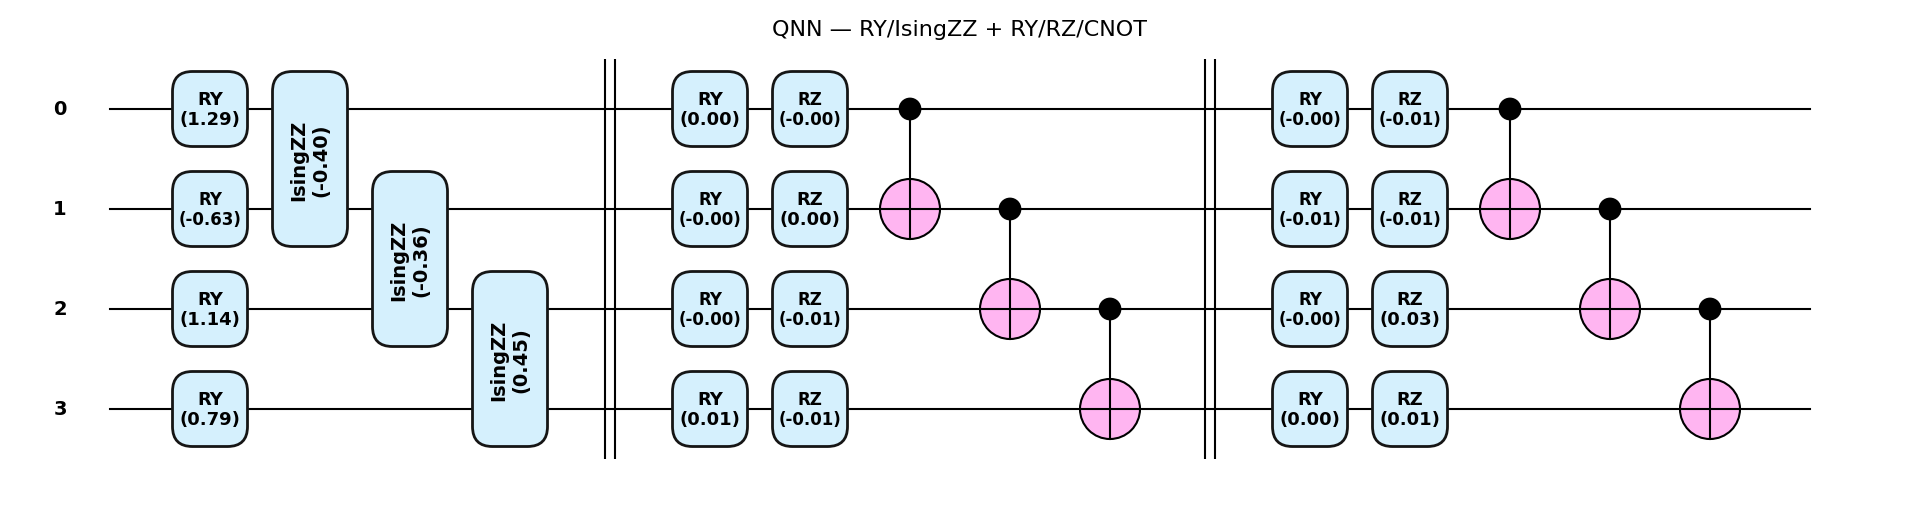

In [ ]:
fig, ax = qml.draw_mpl(circuito_base, decimals=2, style="pennylane")(X_train_t[0], parametros.detach())  # Dibujar el circuito completo con datos y parámetros iniciales
fig.suptitle("QNN — RY/IsingZZ + RY/RZ/CNOT", fontsize=16)                                             # Añadir título
plt.show()                                                                                             # Visualizar el circuito integrado

Hemos construido nuestra **Red Neuronal Cuántica Variacional**, integrando:

- **Feature Map:** cuatro rotaciones $R_Y$ e interacciones $\mathrm{IsingZZ}$ entre qubits vecinos.
- **Ansatz:** dos capas de rotaciones $R_Y$, $R_Z$ y entrelazamiento CNOT, con **16 parámetros entrenables**.
- **PennyLane:** construcción y simulación del circuito cuántico, independientemente de la interfaz utilizada para calcular gradientes.

Para obtener predicciones de las tres especies, necesitamos definir **qué medimos**, **cómo interpretamos los resultados** y **cómo entrenamos los parámetros**. A continuación compararemos tres métodos de clasificación manteniendo esta arquitectura y utilizando **PyTorch como interfaz de diferenciación automática**.

<a name="seccion-4"></a>

# **4. Métodos de Medición y Clasificación Cuántica Variacional**

Una vez construido el circuito de nuestra **QNN**, transformaremos sus mediciones en predicciones para las tres especies de Iris. Compararemos **tres métodos** que comparten la misma arquitectura, datos de entrenamiento, validación e inicialización de parámetros:

1. **Probabilidades computacionales:** sumar las probabilidades de los estados asignados a cada especie.
2. **Valores esperados:** convertir cuatro mediciones de Pauli $Z$ en tres puntuaciones de clasificación.
3. **Fidelidad:** comparar el estado generado con tres estados objetivo.

Entrenaremos cada método durante **50 épocas** mediante Adam. Al finalizar cada época calcularemos la pérdida y el accuracy en **entrenamiento y validación**; conservaremos los parámetros de la **época con menor pérdida de validación** y evaluaremos ese modelo una sola vez sobre **prueba**. Las barras de progreso mostrarán las métricas actualizadas y cada método imprimirá su **matriz de confusión en prueba**.

### Interfaces de Diferenciación Automática y Optimizadores

PennyLane permite construir circuitos cuánticos independientemente de la biblioteca utilizada para entrenarlos. Para calcular los gradientes de una **QNN variacional**, podemos utilizar diferentes interfaces de diferenciación automática: **PyTorch, Autograd y JAX**.

Al definir un QNode con `@qml.qnode`, especificamos tres elementos:

- **Dispositivo (`device`):** simulador o hardware donde se ejecuta el circuito.
- **Interfaz (`interface`):** biblioteca que gestiona la diferenciación automática.
- **Método de diferenciación (`diff_method`):** procedimiento para calcular las derivadas del circuito, como `backprop`, `parameter-shift` o `adjoint`, según la compatibilidad del dispositivo.

Las tres interfaces pueden utilizar `backprop` con `default.qubit`, aunque emplean diferentes mecanismos para obtener los gradientes y actualizar los parámetros.

| Característica | PyTorch | Autograd | JAX |
|---|---|---|---|
| Interfaz | `torch` | `autograd` | `jax` |
| Cálculo de gradientes | `loss.backward()` | `qml.grad()` | `jax.grad()` |
| Optimizador Adam | `torch.optim.Adam` | `qml.AdamOptimizer` | `optax.adam` |
| Principal ventaja | Integración con redes neuronales clásicas | Entrenamiento sencillo de QNN | Compilación JIT y vectorización |

**Ejemplo de declaración del QNode:**

```python
# PyTorch
@qml.qnode(dispositivo_cuantico, interface="torch", diff_method="backprop")

# Autograd
@qml.qnode(dispositivo_cuantico, interface="autograd", diff_method="backprop")

# JAX
@qml.qnode(dispositivo_cuantico, interface="jax", diff_method="backprop")
```

Las tres declaraciones permiten diferenciar un circuito cuántico con el mismo método, pero utilizando motores de diferenciación automática diferentes.

**Elección para este laboratorio:** utilizaremos **PyTorch** mediante `interface="torch"` y `torch.optim.Adam`. Autograd y JAX constituyen alternativas que podrán utilizarse en los proyectos.

**Entrenamiento, selección por validación y evaluación compartidos**

In [ ]:
from sklearn.metrics import confusion_matrix              # Calcular matrices de confusión

EPOCAS = 50                                               # Número fijo de épocas por modelo
BATCH_SIZE = 16                                           # Tamaño de los lotes de entrenamiento
LR = 0.02                                                 # Tasa de aprendizaje del optimizador Adam


def evaluar_modelo(funcion_salida, funcion_perdida, pesos, X_datos, y_datos):
    with torch.no_grad():                                 # Evaluar sin calcular gradientes
        salidas = torch.stack([funcion_salida(x, pesos) for x in X_datos])  # Obtener salidas
        perdida = funcion_perdida(salidas, y_datos).item()  # Calcular pérdida promedio
        predicciones = salidas.argmax(dim=1)              # Seleccionar la clase predicha
        accuracy = (predicciones == y_datos).double().mean().item()  # Calcular exactitud
    return perdida, accuracy, predicciones                # Devolver métricas y predicciones


def entrenar_modelo(funcion_salida, funcion_perdida, nombre):
    pesos = torch.nn.Parameter(parametros.detach().clone())  # Misma inicialización para los tres métodos
    optimizador = torch.optim.Adam([pesos], lr=LR)         # Optimizador Adam
    generador = torch.Generator().manual_seed(SEMILLA)     # Mismo orden de lotes por método
    historial = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc")}  # Historial de métricas
    mejor_loss, mejor_epoca, mejor_pesos = float("inf"), 0, None  # Mejor checkpoint
    total_lotes = (len(X_train_t) + BATCH_SIZE - 1) // BATCH_SIZE  # Lotes por época

    with tqdm(total=EPOCAS * total_lotes, desc=nombre, unit="lote") as barra:
        for epoca in range(EPOCAS):                       # Recorrer las épocas
            indices = torch.randperm(len(X_train_t), generator=generador)  # Mezclar entrenamiento
            loss_acum, aciertos, vistas = 0.0, 0, 0      # Reiniciar métricas acumuladas

            for inicio in range(0, len(indices), BATCH_SIZE):
                idx = indices[inicio:inicio + BATCH_SIZE]  # Seleccionar lote
                salidas = torch.stack([funcion_salida(X_train_t[i], pesos) for i in idx])  # Ejecutar QNN
                perdida = funcion_perdida(salidas, y_train_t[idx])  # Calcular pérdida del lote

                loss_acum += perdida.detach().item() * len(idx)  # Acumular pérdida ponderada
                aciertos += (salidas.argmax(dim=1) == y_train_t[idx]).sum().item()  # Contar aciertos
                vistas += len(idx)                       # Contar muestras procesadas

                optimizador.zero_grad()                   # Limpiar gradientes anteriores
                perdida.backward()                       # Calcular gradientes mediante backprop
                optimizador.step()                       # Actualizar parámetros mediante Adam

                barra.update(1)                          # Actualizar progreso
                barra.set_postfix(epoca=f"{epoca+1}/{EPOCAS}", loss=f"{loss_acum/vistas:.4f}",
                                  acc=f"{aciertos/vistas:.1%}")  # Mostrar métricas acumuladas

            loss_train, acc_train, _ = evaluar_modelo(funcion_salida, funcion_perdida, pesos, X_train_t, y_train_t)
            loss_val, acc_val, _ = evaluar_modelo(funcion_salida, funcion_perdida, pesos, X_val_t, y_val_t)

            for clave, valor in zip(historial, (loss_train, loss_val, acc_train, acc_val)):
                historial[clave].append(valor)            # Registrar métricas de cada época

            if loss_val < mejor_loss:                     # Seleccionar menor pérdida de validación
                mejor_loss, mejor_epoca = loss_val, epoca + 1
                mejor_pesos = pesos.detach().clone()     # Guardar parámetros del mejor modelo

            barra.set_postfix(epoca=f"{epoca+1}/{EPOCAS}", train=f"{acc_train:.1%}",
                              val=f"{acc_val:.1%}", val_loss=f"{loss_val:.4f}")  # Métricas por época

    with torch.no_grad():
        pesos.copy_(mejor_pesos)                         # Restaurar mejor checkpoint
    return pesos, historial, mejor_epoca                 # Devolver resultados del entrenamiento


def mostrar_resultados(nombre, funcion_salida, funcion_perdida, pesos, mejor_epoca):
    resultados = [
        evaluar_modelo(funcion_salida, funcion_perdida, pesos, X, y)
        for X, y in ((X_train_t, y_train_t), (X_val_t, y_val_t), (X_test_t, y_test_t))
    ]                                                     # Evaluar entrenamiento, validación y prueba

    (loss_train, acc_train, _), (loss_val, acc_val, _), (loss_test, acc_test, pred_test) = resultados
    matriz = confusion_matrix(y_test, pred_test.detach().cpu().numpy(), labels=[0, 1, 2])  # Matriz 3×3

    print(f"\n{nombre} | Mejor época: {mejor_epoca}/{EPOCAS}")
    print(f"Accuracy train: {acc_train:.2%} | val: {acc_val:.2%} | test: {acc_test:.2%}")
    print(f"Loss train: {loss_train:.4f} | val: {loss_val:.4f} | test: {loss_test:.4f}")
    print("Matriz de confusión (filas: real; columnas: predicción):\n", matriz)

    return {
        "train_acc": acc_train, "val_acc": acc_val, "test_acc": acc_test,
        "train_loss": loss_train, "val_loss": loss_val, "test_loss": loss_test,
        "best_epoch": mejor_epoca, "confusion": matriz
    }                                                     # Conservar resultados para comparar métodos

## 4.1. Clasificación mediante Probabilidades de Estados Computacionales

El primer método utiliza las **probabilidades de medición en la base computacional** para clasificar las tres especies de Iris.

Nuestro circuito tiene **cuatro qubits**, por lo que el estado cuántico puede expresarse como una superposición de $2^4=16$ estados computacionales:

$$
|\psi(\mathbf{x},\boldsymbol{\theta})\rangle=\sum_{b=0}^{15}\alpha_b|b\rangle
$$

Cada estado $|b\rangle$ tiene una probabilidad de medición determinada por el módulo cuadrado de su amplitud:

$$
\boxed{p_b=P(b|\mathbf{x},\boldsymbol{\theta})=|\langle b|\psi(\mathbf{x},\boldsymbol{\theta})\rangle|^2}
$$

### Obtención de las probabilidades

En PennyLane utilizamos `qml.probs(wires=range(NUM_QUBITS))` para obtener las **16 probabilidades computacionales**. Como el simulador está configurado con `shots=None`, estas se calculan analíticamente, sin realizar un muestreo finito de mediciones.

El resultado es un vector:

$$
\mathbf{p}=(p_0,p_1,\ldots,p_{15}),\qquad \sum_{b=0}^{15}p_b=1
$$

donde cada índice corresponde a un estado computacional, desde $|0000\rangle$ hasta $|1111\rangle$.

### Agrupación de probabilidades por especie

Como necesitamos clasificar **tres especies**, pero obtenemos **16 probabilidades**, asignaremos cada estado computacional a una clase:

| Clase | Especie | Estados computacionales |
|---|---|---|
| 0 | Setosa | 0000, 0011, 0110, 1001, 1100, 1111 |
| 1 | Versicolor | 0001, 0100, 0111, 1010, 1101 |
| 2 | Virginica | 0010, 0101, 1000, 1011, 1110 |

Definimos tres conjuntos de índices $B_0$, $B_1$ y $B_2$. Las probabilidades de cada especie se obtienen **sumando las probabilidades de sus estados asignados**:

$$
\boxed{
\begin{aligned}
P(0|\mathbf{x},\boldsymbol{\theta}) &= p_0+p_3+p_6+p_9+p_{12}+p_{15}\\
P(1|\mathbf{x},\boldsymbol{\theta}) &= p_1+p_4+p_7+p_{10}+p_{13}\\
P(2|\mathbf{x},\boldsymbol{\theta}) &= p_2+p_5+p_8+p_{11}+p_{14}
\end{aligned}
}
$$

En general, este procedimiento se expresa como:

$$
\boxed{P(c|\mathbf{x},\boldsymbol{\theta})=\sum_{b\in B_c}p_b}
$$

Como los conjuntos $B_c$ **no se superponen y abarcan los 16 estados**, obtenemos tres probabilidades que satisfacen:

$$
\boxed{P(0|\mathbf{x},\boldsymbol{\theta})+P(1|\mathbf{x},\boldsymbol{\theta})+P(2|\mathbf{x},\boldsymbol{\theta})=1}
$$

En el código, `salida_a()` implementa estas sumas mediante `probs[g].sum()` y utiliza `torch.stack()` para construir el vector de tres probabilidades.

### Predicción y entrenamiento

Para clasificar una muestra, seleccionamos la especie con la **mayor probabilidad**:

$$
\boxed{\hat y=\underset{c\in\{0,1,2\}}{\arg\max}\ P(c|\mathbf{x},\boldsymbol{\theta})}
$$

Por ejemplo, si obtenemos:

$$
\mathbf P=(0.15,\ 0.70,\ 0.15)
$$

la predicción será **Versicolor (clase 1)**, porque tiene la mayor probabilidad.

Para entrenar los parámetros $\boldsymbol{\theta}$ del circuito, minimizamos la **entropía cruzada** de las clases correctas:

$$
\boxed{\mathcal L_A=-\frac{1}{N}\sum_{i=1}^{N}\log P(y_i|\mathbf{x}_i,\boldsymbol{\theta})}
$$

Esta función penaliza al modelo cuando asigna una probabilidad baja a la especie verdadera. En el código utilizamos `clamp_min(1e-10)` para evitar calcular $\log(0)$ y mantener la estabilidad numérica.

**Importante:** la asignación de estados computacionales a especies es una **decisión de diseño**, no una propiedad física de los bitstrings. Los grupos de 6, 5 y 5 estados tampoco representan las frecuencias de las especies en Iris, sino la forma elegida para transformar las 16 probabilidades en tres clases.

In [ ]:
@qml.qnode(dispositivo_cuantico, interface="torch", diff_method="backprop")  # Crear QNode diferenciable

def qnode_a(x, pesos):                                  # Definir medición computacional
    circuito_base(x, pesos)                              # Ejecutar la misma QNN de cuatro qubits
    return qml.probs(wires=range(NUM_QUBITS))             # Obtener las 16 probabilidades

grupos = [[0, 3, 6, 9, 12, 15],                         # Estados asignados a Setosa
          [1, 4, 7, 10, 13],                            # Estados asignados a Versicolor
          [2, 5, 8, 11, 14]]                            # Estados asignados a Virginica

def salida_a(x, pesos):                                  # Obtener tres probabilidades de clase
    probs = qnode_a(x, pesos)                            # Evaluar las probabilidades computacionales
    return torch.stack([probs[g].sum() for g in grupos])  # Sumar las probabilidades por especie

def perdida_a(salidas, etiquetas):                       # Definir la pérdida del método A
    p = salidas.gather(1, etiquetas[:, None]).squeeze(1) # Seleccionar probabilidades de las clases reales
    return -torch.log(p.clamp_min(1e-10)).mean()          # Calcular la entropía cruzada

pesos_a, historial_a, epoca_a = entrenar_modelo(salida_a, perdida_a, "Método A")  # Entrenar y guardar el mejor checkpoint
resultado_a = mostrar_resultados("Método A", salida_a, perdida_a, pesos_a, epoca_a)  # Imprimir matriz de confusión y métricas

Método A:   0%|          | 0/350 [00:00<?, ?lote/s]


Método A | Mejor época: 50/50
Accuracy train: 83.81% | val: 90.91% | test: 82.61%
Loss train: 0.5003 | val: 0.5194 | test: 0.5954
Matriz de confusión (filas: real; columnas: predicción):
 [[7 0 0]
 [0 6 2]
 [0 2 6]]


## 4.2. Clasificación mediante Valores Esperados de Observables Cuánticos

El segundo método utiliza los **valores esperados del observable de Pauli $Z$** para clasificar las tres especies de Iris. A diferencia del Método A, donde obteníamos 16 probabilidades computacionales, ahora calcularemos **cuatro valores esperados**, uno por cada qubit.

### Obtención de los valores esperados

El observable Pauli $Z$ tiene resultados posibles $+1$ y $-1$, asociados a los estados $|0\rangle$ y $|1\rangle$, respectivamente. Su valor esperado se define como:

$$
\boxed{\langle Z_i\rangle=\langle\psi|Z_i|\psi\rangle=P(q_i=0)-P(q_i=1)}
$$

En PennyLane utilizamos `qml.expval(qml.PauliZ(q))` para calcular analíticamente estos valores (`shots=None`), cada uno perteneciente al intervalo $[-1,1]$.

Al evaluar los cuatro qubits obtenemos:

$$
\boxed{
\mathbf z=
\begin{pmatrix}
\langle Z_0\rangle\\
\langle Z_1\rangle\\
\langle Z_2\rangle\\
\langle Z_3\rangle
\end{pmatrix}
}
$$

En el código, `qnode_b()` devuelve los cuatro valores esperados y `torch.stack()` los agrupa en el vector $\mathbf z$.

### Construcción de las puntuaciones por especie

Como necesitamos **tres clases a partir de cuatro mediciones**, proponemos utilizar los tres primeros valores esperados como contribuciones iniciales y combinar el cuarto con coeficientes $-1,-1,+1$:

$$
\boxed{
\begin{aligned}
s_0&=\langle Z_0\rangle-\langle Z_3\rangle &&\text{(Setosa)}\\
s_1&=\langle Z_1\rangle-\langle Z_3\rangle &&\text{(Versicolor)}\\
s_2&=\langle Z_2\rangle+\langle Z_3\rangle &&\text{(Virginica)}
\end{aligned}
}
$$

Esta operación corresponde a una **transformación clásica fija**:

$$
\boxed{
\mathbf s=A\mathbf z,\qquad
A=
\begin{pmatrix}
1&0&0&-1\\
0&1&0&-1\\
0&0&1&1
\end{pmatrix}
}
$$

En el código, `A @ z` produce las tres puntuaciones $\mathbf s=(s_0,s_1,s_2)^T$. La matriz $A$ es una **decisión de diseño**, no una propiedad física, y sus coeficientes no se entrenan.

Los signos elegidos permiten que $\langle Z_3\rangle$ modifique las diferencias entre las clases. Si tuviera el mismo coeficiente en todas, su contribución se cancelaría al aplicar Softmax.

### Conversión a probabilidades y predicción

Las puntuaciones $s_c$ **no son probabilidades**, pues pueden ser negativas y no necesariamente suman uno. Para interpretarlas como probabilidades, podemos utilizar la función **Softmax**:

$$
\boxed{
P(c|\mathbf{x},\boldsymbol{\theta})=
\frac{e^{s_c}}{e^{s_0}+e^{s_1}+e^{s_2}}
}
$$

Estas probabilidades satisfacen:

$$
\boxed{P(0)+P(1)+P(2)=1}
$$

Como Softmax conserva el orden de las puntuaciones, **no necesitamos calcularla para predecir la especie**:

$$
\boxed{
\hat y=
\underset{c\in\{0,1,2\}}{\arg\max}\ s_c
=
\underset{c\in\{0,1,2\}}{\arg\max}\ P(c)
}
$$

En el código, `salida_b()` devuelve directamente las puntuaciones $\mathbf s$ y `argmax(dim=1)` selecciona la clase predicha sin aplicar Softmax previamente.

### Entrenamiento mediante entropía cruzada

Para entrenar los parámetros $\boldsymbol{\theta}$ del circuito, minimizamos la **entropía cruzada** de las clases correctas:

$$
\boxed{
\mathcal L_B=
-\frac{1}{N}\sum_{i=1}^{N}
\log\left(
\frac{e^{s_{i,y_i}}}{\sum_{c=0}^{2}e^{s_{i,c}}}
\right)
}
$$

Aquí, $s_{i,y_i}$ es la puntuación correspondiente a la especie verdadera de la muestra $i$.

En PyTorch utilizamos `torch.nn.functional.cross_entropy(salidas, etiquetas)`, que **combina internamente LogSoftmax y la pérdida de entropía cruzada**. Por tanto, durante el entrenamiento sí se utiliza la transformación logarítmica asociada a Softmax, pero no necesitamos calcular Softmax por separado.

Únicamente se optimizan los **16 parámetros variacionales del circuito cuántico**; la matriz $A$ permanece fija durante todo el entrenamiento.

In [ ]:
@qml.qnode(dispositivo_cuantico, interface="torch", diff_method="backprop")  # Crear QNode diferenciable

def qnode_b(x, pesos):                                  # Definir medición de valores esperados
    circuito_base(x, pesos)                              # Ejecutar la misma QNN de cuatro qubits
    return tuple(qml.expval(qml.PauliZ(q)) for q in range(NUM_QUBITS))  # Medir cuatro valores de Pauli Z

A = torch.tensor([[1, 0, 0, -1],                         # Puntuación de Setosa
                  [0, 1, 0, -1],                         # Puntuación de Versicolor
                  [0, 0, 1,  1]], dtype=TIPO_DATO)       # Puntuación de Virginica

def salida_b(x, pesos):                                  # Obtener tres puntuaciones de clase
    z = torch.stack(qnode_b(x, pesos))                   # Agrupar los cuatro valores esperados
    return A @ z                                        # Aplicar la transformación clásica fija

def perdida_b(salidas, etiquetas):                       # Definir la pérdida del método B
    return torch.nn.functional.cross_entropy(salidas, etiquetas)  # Calcular Cross-Entropy

pesos_b, historial_b, epoca_b = entrenar_modelo(salida_b, perdida_b, "Método B")  # Entrenar y guardar el mejor checkpoint
resultado_b = mostrar_resultados("Método B", salida_b, perdida_b, pesos_b, epoca_b)  # Imprimir matriz de confusión y métricas

Método B:   0%|          | 0/350 [00:00<?, ?lote/s]


Método B | Mejor época: 50/50
Accuracy train: 91.43% | val: 81.82% | test: 78.26%
Loss train: 0.6641 | val: 0.7343 | test: 0.7423
Matriz de confusión (filas: real; columnas: predicción):
 [[7 0 0]
 [1 4 3]
 [0 1 7]]


## 4.3. Clasificación mediante Fidelidad con Estados Objetivo

El tercer método utiliza la **fidelidad cuántica** para clasificar las tres especies de Iris. A diferencia de los métodos anteriores, ahora compararemos el estado generado por nuestra QNN, $|\psi(\mathbf{x},\boldsymbol{\theta})\rangle$, con **tres estados objetivo**, uno por cada especie.

### Definición de los estados objetivo

Asignaremos a cada especie un estado de la base computacional:

$$
\boxed{
\begin{aligned}
|\phi_0\rangle &= |0000\rangle &&\text{(Setosa)}\\
|\phi_1\rangle &= |0001\rangle &&\text{(Versicolor)}\\
|\phi_2\rangle &= |0010\rangle &&\text{(Virginica)}
\end{aligned}
}
$$

Estos estados son **ortogonales entre sí** y su asignación a las especies es una **decisión de diseño**, no una propiedad física de las clases.

### Obtención de las fidelidades

La fidelidad entre dos estados cuánticos puros mide su grado de coincidencia. Para cada especie calculamos:

$$
\boxed{F_c(\mathbf{x},\boldsymbol{\theta})=|\langle\phi_c|\psi(\mathbf{x},\boldsymbol{\theta})\rangle|^2}
$$

Como los estados objetivo pertenecen a la base computacional, sus fidelidades coinciden directamente con las probabilidades de los tres estados seleccionados:

$$
\boxed{
\begin{aligned}
F_0&=P(0000)=p_0\\
F_1&=P(0001)=p_1\\
F_2&=P(0010)=p_2
\end{aligned}
}
$$

En PennyLane podemos obtenerlas mediante `qml.probs(wires=range(NUM_QUBITS))`, seleccionando las posiciones `0`, `1` y `2`. Como utilizamos `shots=None`, las probabilidades se calculan analíticamente, **sin necesidad de implementar un SWAP Test**.

Así obtenemos el vector:

$$
\boxed{\mathbf F=(F_0,F_1,F_2)}
$$

A diferencia del Método A, aquí **no agrupamos las 16 probabilidades**: utilizamos únicamente tres. Por ello, las fidelidades satisfacen:

$$
\boxed{0\leq F_0+F_1+F_2\leq 1}
$$

Los otros trece estados computacionales pueden conservar parte de la probabilidad total.

### Predicción mediante máxima fidelidad

La **predicción** corresponde a la especie cuyo estado objetivo presenta mayor fidelidad con el estado generado:

$$
\boxed{\hat y=\underset{c\in\{0,1,2\}}{\arg\max}\ F_c}
$$

Por ejemplo, si obtenemos:

$$
\mathbf F=(0.10,\ 0.35,\ 0.20)
$$

la predicción será **Versicolor (clase 1)**, porque su estado objetivo tiene la mayor fidelidad. La probabilidad restante, $0.35$, corresponde a los otros trece estados y no interviene directamente en la decisión.

### Entrenamiento mediante maximización de fidelidad

El objetivo del entrenamiento es **aumentar la fidelidad correspondiente a la especie verdadera**. Para ello, minimizaremos:

$$
\boxed{\mathcal L_C=1-\frac{1}{N}\sum_{i=1}^{N}F_{y_i}(\mathbf{x}_i,\boldsymbol{\theta})}
$$

Esta función alcanza su mínimo cuando las muestras tienen fidelidad uno con sus respectivos estados objetivo.

A diferencia de los métodos A y B, **no utilizamos entropía cruzada**. La función de pérdida maximiza directamente la fidelidad promedio de las clases correctas mediante la optimización de los **16 parámetros variacionales del circuito cuántico**.

**Importante:** aunque el Método C utiliza probabilidades computacionales para calcular las fidelidades, no equivale al Método A. El primero utiliza tres estados objetivo individuales, mientras que el segundo agrupa las probabilidades de los dieciséis estados para construir tres clases.

In [ ]:
@qml.qnode(dispositivo_cuantico, interface="torch", diff_method="backprop")  # Crear QNode diferenciable

def qnode_c(x, pesos):                                  # Definir medición para las fidelidades
    circuito_base(x, pesos)                              # Ejecutar la misma QNN de cuatro qubits
    return qml.probs(wires=range(NUM_QUBITS))             # Obtener probabilidades computacionales

def salida_c(x, pesos):                                  # Obtener las tres fidelidades objetivo
    probs = qnode_c(x, pesos)                            # Evaluar las probabilidades del circuito
    return probs[:3]                                     # Seleccionar |0000>, |0001> y |0010>

def perdida_c(salidas, etiquetas):                       # Definir la pérdida del método C
    F = salidas.gather(1, etiquetas[:, None]).squeeze(1) # Extraer fidelidad de la clase verdadera
    return 1.0 - F.mean()                                # Maximizar la fidelidad de la clase real

pesos_c, historial_c, epoca_c = entrenar_modelo(salida_c, perdida_c, "Método C")  # Entrenar y guardar el mejor checkpoint
resultado_c = mostrar_resultados("Método C", salida_c, perdida_c, pesos_c, epoca_c)  # Imprimir matriz de confusión y métricas

Método C:   0%|          | 0/350 [00:00<?, ?lote/s]


Método C | Mejor época: 16/50
Accuracy train: 93.33% | val: 95.45% | test: 91.30%
Loss train: 0.5296 | val: 0.5890 | test: 0.5829
Matriz de confusión (filas: real; columnas: predicción):
 [[7 0 0]
 [0 8 0]
 [0 2 6]]



## 4.4. Comparación y Evaluación de los Clasificadores Cuánticos

Compararemos la evolución de los **tres modelos** mediante cuatro gráficas: **pérdida en entrenamiento, pérdida en validación, accuracy en entrenamiento y accuracy en validación**. Cada curva corresponde a las métricas calculadas al finalizar una época; el checkpoint final de cada método es el de **menor pérdida de validación**.

La tabla resumirá la época seleccionada y el accuracy de **entrenamiento, validación y prueba**. El conjunto de prueba **no interviene en la selección del modelo**.

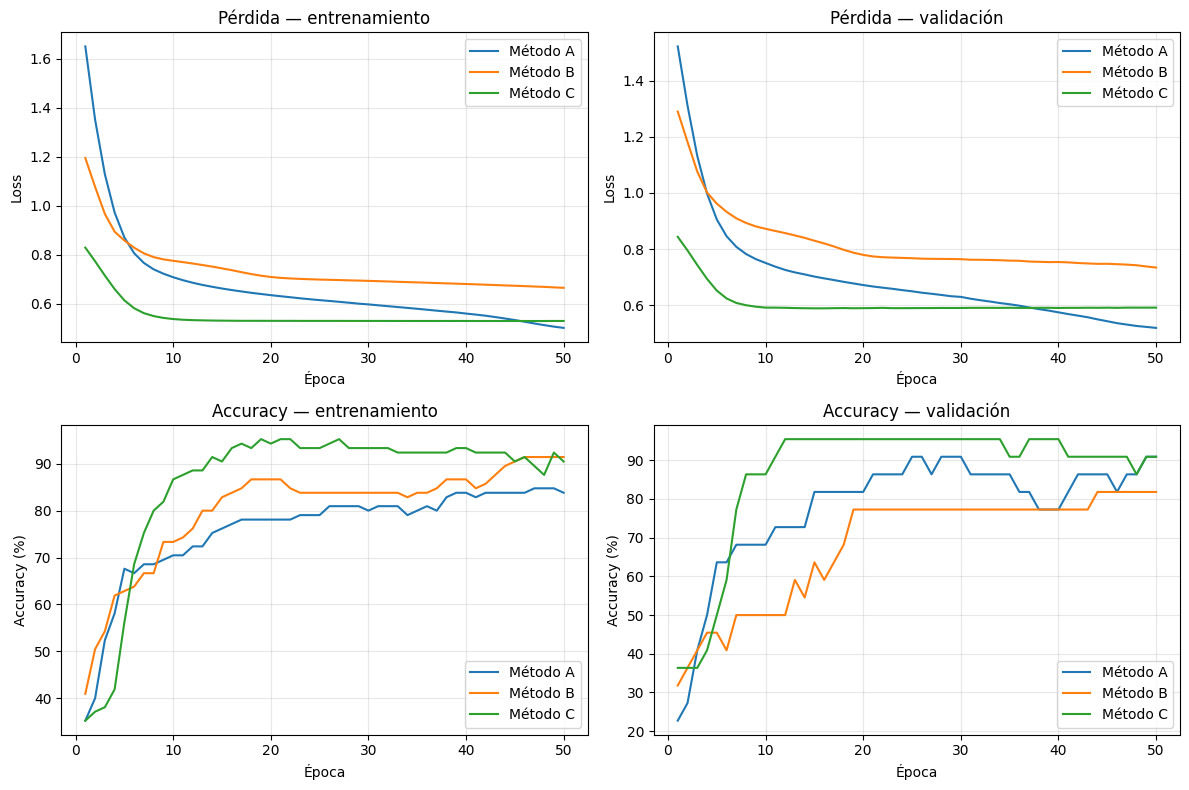

Modelo        Mejor época      Train        Val       Test
----------------------------------------------------------
Método A               50    83.81%    90.91%    82.61%
Método B               50    91.43%    81.82%    78.26%
Método C               16    93.33%    95.45%    91.30%


In [ ]:
modelos = {"Método A": (historial_a, resultado_a),       # Reunir las curvas y resultados del método A
           "Método B": (historial_b, resultado_b),       # Reunir las curvas y resultados del método B
           "Método C": (historial_c, resultado_c)}       # Reunir las curvas y resultados del método C

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))          # Crear exactamente cuatro gráficas
metricas = [("train_loss", "Pérdida — entrenamiento"),  # Seleccionar pérdida de entrenamiento
            ("val_loss", "Pérdida — validación"),         # Seleccionar pérdida de validación
            ("train_acc", "Accuracy — entrenamiento"),  # Seleccionar accuracy de entrenamiento
            ("val_acc", "Accuracy — validación")]       # Seleccionar accuracy de validación

for ax, (clave, titulo) in zip(ejes.flat, metricas):    # Recorrer las cuatro gráficas
    for nombre, (historial, _) in modelos.items():       # Dibujar los tres clasificadores
        valores = np.array(historial[clave])             # Extraer la curva correspondiente
        if "acc" in clave: valores = 100 * valores       # Convertir accuracy a porcentaje
        ax.plot(range(1, EPOCAS + 1), valores, label=nombre)  # Graficar por época
    ax.set_title(titulo)                                # Añadir título a cada gráfica
    ax.set_xlabel("Época")                               # Etiquetar el eje horizontal
    ax.set_ylabel("Accuracy (%)" if "acc" in clave else "Loss")  # Identificar la métrica
    ax.grid(alpha=0.3)                                  # Incorporar cuadrícula suave
    ax.legend()                                         # Identificar los tres modelos

plt.tight_layout()                                      # Evitar superposición de elementos
plt.show()                                              # Mostrar las cuatro gráficas

print(f"{'Modelo':<12} {'Mejor época':>12} {'Train':>10} {'Val':>10} {'Test':>10}")  # Encabezado de la tabla
print("-" * 58)                                          # Separar encabezado y resultados
for nombre, (_, resultado) in modelos.items():          # Mostrar un registro por clasificador
    print(f"{nombre:<12} {resultado['best_epoch']:>12} "
          f"{resultado['train_acc']:>9.2%} {resultado['val_acc']:>9.2%} "
          f"{resultado['test_acc']:>9.2%}")             # Imprimir la tabla comparativa

# **Conclusión**

En este laboratorio construimos y entrenamos una **Red Neuronal Cuántica Variacional (QNN)** para clasificar las tres especies del conjunto de datos Iris, comparando tres métodos de medición sobre una misma arquitectura cuántica.

Los resultados mostraron que el **Método C (fidelidad con estados objetivo)** obtuvo el mejor desempeño, con una exactitud del **91.30% en prueba**, seguido del **Método A (probabilidades computacionales)** con **82.61%** y del **Método B (valores esperados de Pauli Z)** con **78.26%**.

Estos resultados muestran que **la elección del método de medición y clasificación influye en el rendimiento del modelo**, incluso cuando se utiliza el mismo circuito cuántico. Sin embargo, las diferencias observadas corresponden a esta configuración experimental y no establecen que un método sea universalmente superior.

### Referencias de recursos visuales

Nuer, J. (2021). *Neural Networks For Dummies*. Medium. [Artículo](https://medium.com/@jereminuerofficial/neural-networks-for-dummies-bc1ed3f69027).

Medium. *Animación de una neurona artificial*. [GIF](https://cdn-images-1.medium.com/max/732/1*KNZZYteeBqkJViS1_LT1CQ.gif). Autor original no identificado.

Medium. *Animación de redes neuronales*. [GIF](https://miro.medium.com/v2/resize:fit:640/0*0gv8Cs0UaB49ZNKZ.gif). Autor original no identificado.

gbhat.com. *Linear Regression*. [Artículo y animación](https://gbhat.com/machine_learning/linear_regression.html).

3Blue1Brown. *Animación de retropropagación*, reproducida en Alake, R. (2022). *A Data Scientist's Guide to Gradient Descent and Backpropagation Algorithms*. NVIDIA Technical Blog. [Artículo](https://developer.nvidia.com/blog/a-data-scientists-guide-to-gradient-descent-and-backpropagation-algorithms/).

Gupta, S. (2017). *Gradient Descent*. [Artículo y animación](https://sar-gupta.github.io/posts/2017/10/20/gradient-descent). El artículo atribuye la animación original a Alykhan Tejani.


---

Desarrollado por Sebastián González Juárez
Facultad de Ciencias, Universidad Nacional Autónoma de México (UNAM)


© 2026 Sebastián González Juárez. Este notebook fue desarrollado con fines educativos y de investigación. Si el material es reutilizado o adaptado, se agradece conservar la atribución al autor.

  <li><b>Repositorio personal del autor Sebastián González Juárez:</b><br>
<a href="https://github.com/Bayan0708" target="_blank">
https://github.com/Bayan0708
</a>